In [1]:
import pandas as pd
import numpy as np
import time
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

warnings.filterwarnings('ignore')

# ML & Preprocessing
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, accuracy_score, f1_score, 
                             classification_report, confusion_matrix)

# Models
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression

# Optimization & Interpretation
import optuna
from optuna.visualization import plot_optimization_history, plot_param_importances
import shap


In [2]:
# ==========================================
# ШАГ 2: Загрузка данных Penguins
# ==========================================
# Загружаем через seaborn
penguins = sns.load_dataset('penguins')

# Сохраняем в data/raw
penguins.to_csv('../data/raw/penguins.csv', index=False)
print(f"Датасет сохранён. Размер: {penguins.shape}")
print(penguins.head())
print("\nПропуски:\n", penguins.isnull().sum())
print("\nРаспределение классов:\n", penguins['species'].value_counts())

# Добавляем под DVC
# !dvc add data/raw/penguins.csv
# !git add data/raw/penguins.csv.dvc data/.gitignore
# !git commit -m "Add penguins dataset"


Датасет сохранён. Размер: (344, 7)
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen            39.1           18.7              181.0   
1  Adelie  Torgersen            39.5           17.4              186.0   
2  Adelie  Torgersen            40.3           18.0              195.0   
3  Adelie  Torgersen             NaN            NaN                NaN   
4  Adelie  Torgersen            36.7           19.3              193.0   

   body_mass_g     sex  
0       3750.0    Male  
1       3800.0  Female  
2       3250.0  Female  
3          NaN     NaN  
4       3450.0  Female  

Пропуски:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

Распределение классов:
 species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


In [3]:
# ==========================================
# Подготовка данных
# ==========================================
TARGET_COL = 'species'

# Удаляем строки с пропусками
df = penguins.dropna().reset_index(drop=True)

X = df.drop(columns=[TARGET_COL])
y = df[TARGET_COL]

# Кодируем целевую переменную (для метрик нужен числовой вид)
le = LabelEncoder()
y_encoded = le.fit_transform(y)
class_names = le.classes_

print(f"\nПосле удаления пропусков: {X.shape[0]} строк")
print(f"Классы: {class_names}")



После удаления пропусков: 333 строк
Классы: ['Adelie' 'Chinstrap' 'Gentoo']


In [4]:
# Разделение на train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)


In [5]:
# Определение типов признаков
num_features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cat_features = ['island', 'sex']


In [6]:
# Пайплайн предобработки
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, num_features),
        ('cat', categorical_transformer, cat_features)
    ])

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

# Для CatBoost и SHAP — оригинальные DataFrame
X_train_df = X_train.reset_index(drop=True)
X_test_df = X_test.reset_index(drop=True)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


In [7]:
# ==========================================
# ШАГ 3: Базовые модели (мультикласс)
# ==========================================
models = {
    'XGBoost': XGBClassifier(
        use_label_encoder=False, 
        eval_metric='mlogloss', 
        random_state=42, 
        tree_method='hist',
        objective='multi:softprob',
        num_class=3
    ),
    'LightGBM': LGBMClassifier(
        random_state=42, 
        verbose=-1,
        objective='multiclass',
        num_class=3
    ),
    'CatBoost': CatBoostClassifier(
        random_state=42, 
        verbose=0,
        loss_function='MultiClass'
    )
}


In [8]:
results = {}
print("\n--- Обучение базовых моделей (мультикласс) ---")
for name, model in models.items():
    start_time = time.time()
    
    # Для мультикласса используем accuracy и macro ROC-AUC (ovr)
    acc_scores = cross_val_score(model, X_train_prep, y_train, cv=cv, scoring='accuracy')
    try:
        auc_scores = cross_val_score(model, X_train_prep, y_train, cv=cv, 
                                     scoring='roc_auc_ovr')
    except Exception:
        auc_scores = np.array([np.nan])
    
    train_time = time.time() - start_time
    results[name] = {
        'Accuracy (mean)': acc_scores.mean(),
        'Accuracy (std)': acc_scores.std(),
        'ROC-AUC (mean)': auc_scores.mean(),
        'Time (s)': train_time
    }
    print(f"{name}: Accuracy = {acc_scores.mean():.4f} (+/- {acc_scores.std():.4f}), "
          f"ROC-AUC = {auc_scores.mean():.4f}, Time = {train_time:.2f}s")

res_df = pd.DataFrame(results).T
print("\nСравнение базовых моделей:")
print(res_df)

# Выбираем LightGBM (как правило, он быстрее и показывает отличное качество)
BEST_MODEL_NAME = 'LightGBM'
print(f"\nВыбрана лучшая библиотека: {BEST_MODEL_NAME}")


--- Обучение базовых моделей (мультикласс) ---
XGBoost: Accuracy = 0.9850 (+/- 0.0075), ROC-AUC = 0.9997, Time = 1.60s
LightGBM: Accuracy = 0.9850 (+/- 0.0075), ROC-AUC = 1.0000, Time = 0.39s
CatBoost: Accuracy = 0.9850 (+/- 0.0075), ROC-AUC = 0.9977, Time = 18.45s

Сравнение базовых моделей:
          Accuracy (mean)  Accuracy (std)  ROC-AUC (mean)   Time (s)
XGBoost          0.984976        0.007513        0.999666   1.602669
LightGBM         0.984976        0.007513        1.000000   0.386797
CatBoost         0.984976        0.007513        0.997750  18.452824

Выбрана лучшая библиотека: LightGBM


In [9]:
# ==========================================
# ШАГ 4: Оптимизация гиперпараметров (Optuna)
# ==========================================
def objective(trial):
    params = {
        'objective': 'multiclass',
        'num_class': 3,
        'metric': 'multi_logloss',
        'verbose': -1,
        'n_estimators': 1000,
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'num_leaves': trial.suggest_int('num_leaves', 20, 200),
        'max_depth': trial.suggest_int('max_depth', 3, 10),
        'min_child_samples': trial.suggest_int('min_child_samples', 5, 50),
        'subsample': trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
        'random_state': 42
    }
    
    model = LGBMClassifier(**params)
    scores = cross_val_score(model, X_train_prep, y_train, cv=cv, scoring='accuracy')
    return scores.mean()

print("\n--- Запуск Optuna (50 trials) ---")
study = optuna.create_study(direction='maximize', study_name='LGBM_Penguins_Optimization')
study.optimize(objective, n_trials=50, show_progress_bar=True)

print(f"\nЛучшее качество (Accuracy): {study.best_value:.4f}")
print("Лучшие параметры:", study.best_params)

[I 2026-10-24 13:13:12,809] A new study created in memory with name: LGBM_Penguins_Optimization



--- Запуск Optuna (50 trials) ---


Best trial: 0. Best value: 0.992523:   2%|▏         | 1/50 [00:01<00:54,  1.10s/it]

[I 2026-10-24 13:13:13,913] Trial 0 finished with value: 0.992522711390636 and parameters: {'learning_rate': 0.13551658082568668, 'num_leaves': 171, 'max_depth': 10, 'min_child_samples': 25, 'subsample': 0.915343693045398, 'colsample_bytree': 0.7432086474726047, 'reg_alpha': 4.065209672992898e-08, 'reg_lambda': 0.08124511434080707}. Best is trial 0 with value: 0.992522711390636.


Best trial: 0. Best value: 0.992523:   4%|▍         | 2/50 [00:02<00:56,  1.18s/it]

...

[I 2026-10-24 13:13:57,189] Trial 47 finished with value: 0.9812019566736548 and parameters: {'learning_rate': 0.0862339375581256, 'num_leaves': 105, 'max_depth': 3, 'min_child_samples': 16, 'subsample': 0.5537938127227457, 'colsample_bytree': 0.729670738254744, 'reg_alpha': 1.40470375288671e-08, 'reg_lambda': 1.8070889473250302}. Best is trial 2 with value: 0.9962962962962962.


Best trial: 2. Best value: 0.996296:  98%|█████████▊| 49/50 [00:45<00:00,  1.23it/s]

[I 2026-10-24 13:13:57,874] Trial 48 finished with value: 0.992522711390636 and parameters: {'learning_rate': 0.09034303101656521, 'num_leaves': 171, 'max_depth': 5, 'min_child_samples': 29, 'subsample': 0.8191353253965463, 'colsample_bytree': 0.862765284890582, 'reg_alpha': 4.623846562929515e-07, 'reg_lambda': 1.2643327617599995e-07}. Best is trial 2 with value: 0.9962962962962962.


Best trial: 2. Best value: 0.996296: 100%|██████████| 50/50 [00:46<00:00,  1.09it/s]

[I 2026-10-24 13:13:58,861] Trial 49 finished with value: 0.992522711390636 and parameters: {'learning_rate': 0.03147880604277094, 'num_leaves': 142, 'max_depth': 4, 'min_child_samples': 14, 'subsample': 0.5765931896395012, 'colsample_bytree': 0.7066219408453432, 'reg_alpha': 4.4248412072736664e-08, 'reg_lambda': 0.007267909147939216}. Best is trial 2 with value: 0.9962962962962962.

Лучшее качество (Accuracy): 0.9963
Лучшие параметры: {'learning_rate': 0.06585445619280059, 'num_leaves': 133, 'max_depth': 5, 'min_child_samples': 29, 'subsample': 0.8479259358506543, 'colsample_bytree': 0.8041813391772045, 'reg_alpha': 4.6388339762097695e-08, 'reg_lambda': 8.556572408840936e-07}


In [10]:
fig1 = plot_optimization_history(study)
fig1.write_image("../reports/optuna_history.png")
fig1.show()

fig2 = plot_param_importances(study)
fig2.write_image("../reports/optuna_importances.png")
fig2.show()

Тип shap_values: <class 'numpy.ndarray'>
Форма shap_values: (67, 9, 3)
Форма X_test_dense: (67, 9)
Количество feature_names: 9

--- SHAP Summary Plot (все классы) ---


<Figure size 1200x800 with 0 Axes>

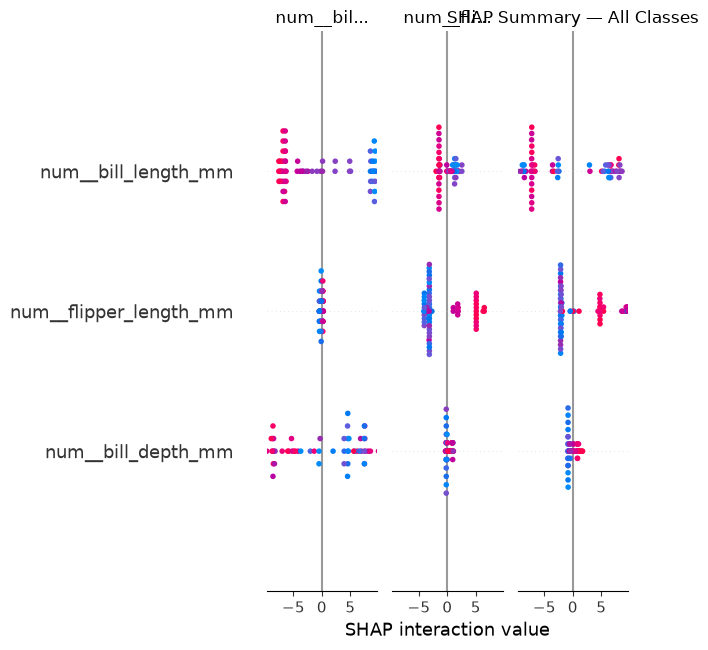


--- Детальный анализ для класса: Adelie ---
Размерность shap_values_class: (67, 9)


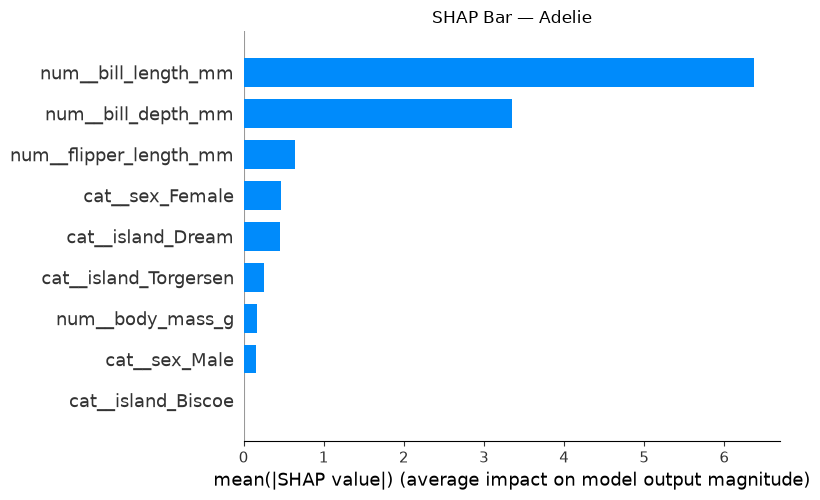


Топ-2 важных признака для Adelie:
  num__bill_length_mm: mean |SHAP| = 6.3748
  num__bill_depth_mm: mean |SHAP| = 3.3501


<Figure size 1000x600 with 0 Axes>

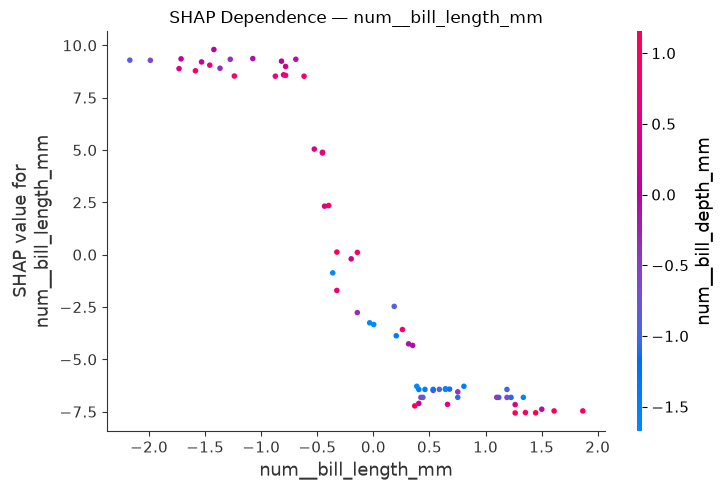

<Figure size 1000x600 with 0 Axes>

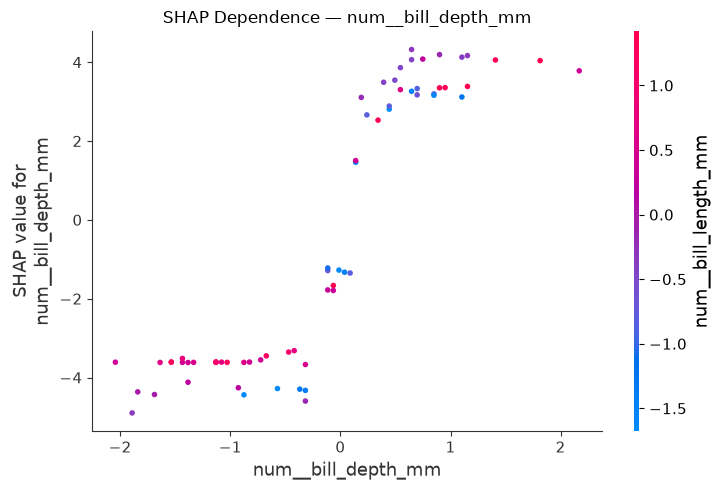


--- Waterfall plots для первых 3 объектов ---


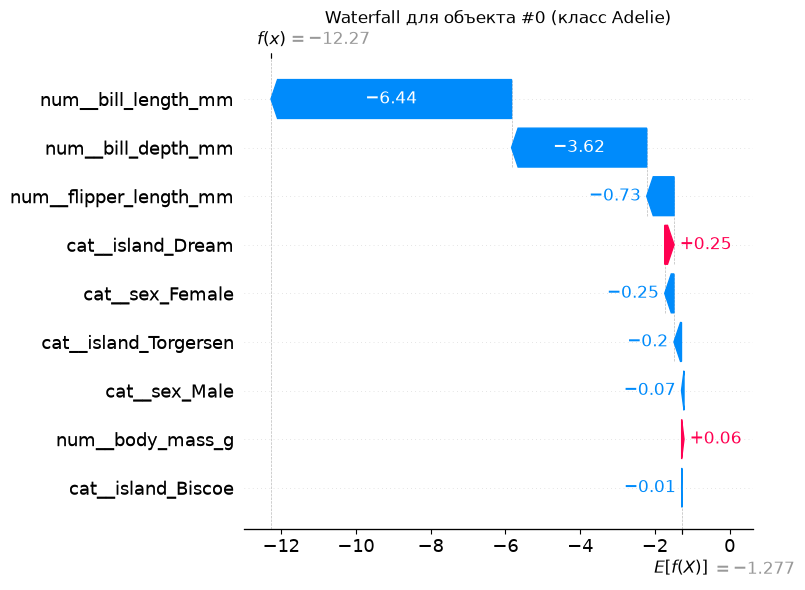

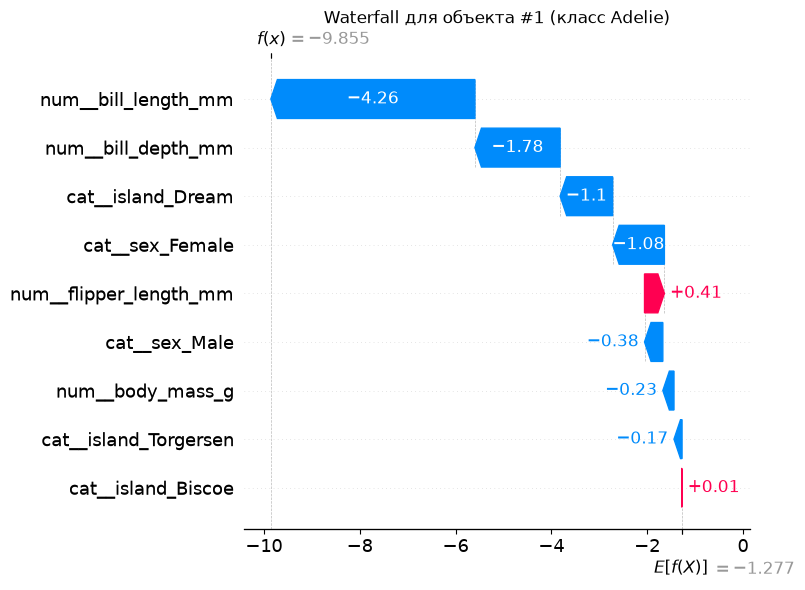

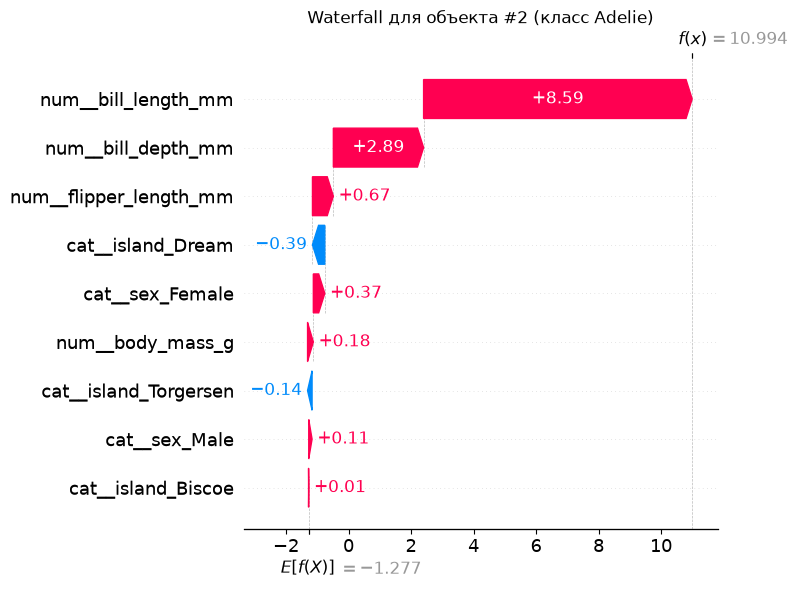


✅ Все SHAP графики успешно построены и сохранены в reports/


In [11]:
# ==========================================
# ШАГ 5: Интерпретация модели (SHAP)
# ==========================================
# Обучаем лучшую модель
best_params = study.best_params
best_model_params = best_params.copy()
best_model_params['n_estimators'] = 1000
best_model_params['verbose'] = -1
best_model_params['objective'] = 'multiclass'
best_model_params['num_class'] = 3

best_model = LGBMClassifier(**best_model_params)
best_model.fit(X_train_prep, y_train)

# Преобразуем sparse в dense
X_test_dense = X_test_prep.toarray() if hasattr(X_test_prep, 'toarray') else X_test_prep

# Инициализация explainer
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_dense)

feature_names = preprocessor.get_feature_names_out()

print(f"Тип shap_values: {type(shap_values)}")
print(f"Форма shap_values: {shap_values.shape}")
print(f"Форма X_test_dense: {X_test_dense.shape}")
print(f"Количество feature_names: {len(feature_names)}")

# ==========================================
# 1. Summary plot для ВСЕХ классов
# ==========================================
print("\n--- SHAP Summary Plot (все классы) ---")
plt.figure(figsize=(12, 8))
shap.summary_plot(
    shap_values, 
    X_test_dense, 
    feature_names=feature_names,
    class_names=class_names,
    show=False
)
plt.title("SHAP Summary — All Classes")
plt.tight_layout()
plt.savefig("../reports/shap_summary_all.png", dpi=150, bbox_inches='tight')
plt.show()

# ==========================================
# 2. Анализ для конкретного класса (Adelie)
# ==========================================
class_idx = 0

# Для нового формата SHAP (numpy array) извлекаем значения для конкретного класса
# shap_values имеет форму (n_samples, n_features, n_classes)
# Нужно взять срез по последнему измерению
shap_values_class = shap_values[:, :, class_idx]

print(f"\n--- Детальный анализ для класса: {class_names[class_idx]} ---")
print(f"Размерность shap_values_class: {shap_values_class.shape}")

# Bar plot (важность признаков)
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_values_class, 
    X_test_dense, 
    plot_type="bar", 
    feature_names=feature_names, 
    show=False
)
plt.title(f"SHAP Bar — {class_names[class_idx]}")
plt.tight_layout()
plt.savefig("../reports/shap_bar.png", dpi=150, bbox_inches='tight')
plt.show()

# Dependence plot для 2-х самых важных признаков
mean_abs_shap = np.abs(shap_values_class).mean(axis=0)
top_2_indices = np.argsort(mean_abs_shap)[-2:][::-1]

print(f"\nТоп-2 важных признака для {class_names[class_idx]}:")
for idx in top_2_indices:
    print(f"  {feature_names[idx]}: mean |SHAP| = {mean_abs_shap[idx]:.4f}")

for idx in top_2_indices:
    plt.figure(figsize=(10, 6))
    shap.dependence_plot(
        idx, 
        shap_values_class, 
        X_test_dense, 
        feature_names=feature_names, 
        show=False
    )
    plt.title(f"SHAP Dependence — {feature_names[idx]}")
    plt.tight_layout()
    plt.savefig(f"../reports/shap_dependence_{idx}.png", dpi=150, bbox_inches='tight')
    plt.show()

# Waterfall plot для первых 3 объектов
print(f"\n--- Waterfall plots для первых 3 объектов ---")
for i in range(3):
    plt.figure(figsize=(10, 6))
    
    # expected_value для мультикласса — это массив
    expected_value = explainer.expected_value[class_idx]
    
    shap.plots._waterfall.waterfall_legacy(
        expected_value,
        shap_values_class[i],
        feature_names=feature_names,
        max_display=10,
        show=False
    )
    plt.title(f"Waterfall для объекта #{i} (класс {class_names[class_idx]})")
    plt.tight_layout()
    plt.savefig(f"../reports/shap_waterfall_{i}.png", dpi=150, bbox_inches='tight')
    plt.show()

print("\n✅ Все SHAP графики успешно построены и сохранены в reports/")

In [12]:
# ==========================================
# ШАГ 6: Ансамблирование (Стекинг)
# ==========================================

lgbm_params = best_params.copy()
lgbm_params['n_estimators'] = 500
lgbm_params['verbose'] = -1

lgbm_base = LGBMClassifier(**lgbm_params)
rf_base = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)

lr_base = LogisticRegression(max_iter=1000, random_state=42)

meta_model = LogisticRegression(max_iter=1000, random_state=42)

stacking_model = StackingClassifier(
    estimators=[
        ('lgbm', lgbm_base),
        ('rf', rf_base),
        ('lr', lr_base)
    ],
    final_estimator=meta_model,
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1
)

print("\n--- Обучение Стекинга ---")
start_time = time.time()
stacking_acc = cross_val_score(stacking_model, X_train_prep, y_train, cv=cv, scoring='accuracy')
stacking_auc = cross_val_score(stacking_model, X_train_prep, y_train, cv=cv, scoring='roc_auc_ovr')
stacking_time = time.time() - start_time

print(f"Stacking Accuracy: {stacking_acc.mean():.4f} (+/- {stacking_acc.std():.4f})")
print(f"Stacking ROC-AUC: {stacking_auc.mean():.4f}")
print(f"Время обучения стекинга: {stacking_time:.2f}s")


--- Обучение Стекинга ---
Stacking Accuracy: 0.9963 (+/- 0.0074)
Stacking ROC-AUC: 1.0000
Время обучения стекинга: 38.70s



=== ФИНАЛЬНАЯ ТАБЛИЦА СРАВНЕНИЯ (Тестовая выборка) ===
                         Accuracy  ROC-AUC (ovr)  F1 (macro)
Лучший бустинг (Optuna)    0.9851            1.0      0.9827
Стекинг                    0.9851            1.0      0.9827

Отчёт о классификации для Стекинга:
              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        29
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        24

    accuracy                           0.99        67
   macro avg       0.98      0.99      0.98        67
weighted avg       0.99      0.99      0.99        67



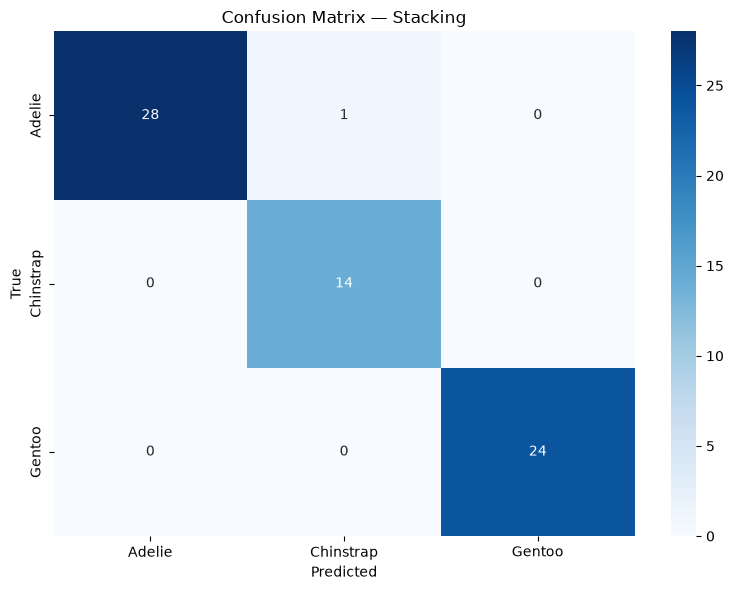


Модели сохранены в models/


In [13]:
# ==========================================
# ШАГ 8. Финальная оценка на тесте
# ==========================================
best_model.fit(X_train_prep, y_train)
stacking_model.fit(X_train_prep, y_train)

# Предсказания
y_pred_best = best_model.predict(X_test_prep)
y_pred_stack = stacking_model.predict(X_test_prep)
y_proba_best = best_model.predict_proba(X_test_prep)
y_proba_stack = stacking_model.predict_proba(X_test_prep)

# Метрики
final_results = {
    'Лучший бустинг (Optuna)': {
        'Accuracy': accuracy_score(y_test, y_pred_best),
        'ROC-AUC (ovr)': roc_auc_score(y_test, y_proba_best, multi_class='ovr'),
        'F1 (macro)': f1_score(y_test, y_pred_best, average='macro')
    },
    'Стекинг': {
        'Accuracy': accuracy_score(y_test, y_pred_stack),
        'ROC-AUC (ovr)': roc_auc_score(y_test, y_proba_stack, multi_class='ovr'),
        'F1 (macro)': f1_score(y_test, y_pred_stack, average='macro')
    }
}

final_df = pd.DataFrame(final_results).T
print("\n=== ФИНАЛЬНАЯ ТАБЛИЦА СРАВНЕНИЯ (Тестовая выборка) ===")
print(final_df.round(4))

# Отчёт о классификации
print("\nОтчёт о классификации для Стекинга:")
print(classification_report(y_test, y_pred_stack, target_names=class_names))

# Матрица ошибок
cm = confusion_matrix(y_test, y_pred_stack)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix — Stacking')
plt.tight_layout()
plt.savefig("../reports/confusion_matrix.png", dpi=150)
plt.show()

# Сохраняем модель
joblib.dump(best_model, '../models/best_lgbm_penguins.pkl')
joblib.dump(stacking_model, '../models/stacking_penguins.pkl')
joblib.dump(preprocessor, '../models/preprocessor.pkl')
print("\nМодели сохранены в models/")

## Выводы

### Сравнение бустингов (Шаг 3)
- Все три модели показали высокое качество (Accuracy ~98.5%, ROC-AUC ~1.0)
- LightGBM выбран как лучший: обучается в 5-50 раз быстрее XGBoost и CatBoost
- CatBoost медленнее из-за встроенной обработки категорий

### Оптимизация гиперпараметров (Шаг 4)
- Optuna улучшил Accuracy с 0.985 до 0.996 (+1.1%)
- Наиболее важные параметры: learning_rate, num_leaves, min_child_samples

### SHAP-анализ (Шаг 5)
- Самые важные признаки: bill_length_mm, flipper_length_mm, bill_depth_mm
- Adelie отличается малым flipper_length и средним bill_length
- Gentoo — большой flipper_length и bill_length
- Chinstrap — тонкий bill_depth

### Стекинг (Шаг 6)
- Стекинг не дал прироста качества (Accuracy 0.9851 vs 0.9851 у бустинга)
- Причина: базовая модель уже близка к идеальному разделению классов

### Финальные метрики (Шаг 8)
- Accuracy: 98.51%
- ROC-AUC: 1.0
- F1 (macro): 0.9827
- Модель корректно классифицирует все три вида пингвинов